# An O+O event, start to finish, with the Pythonic interface

This notebook runs **3 O+O events at 200 GeV** through the full X-SCAPE chain, writes the
hadrons to HDF5, reads them back and finds jets with FastJet, using the Pythonic layer of
PyJetscape (`contribs/PyJetscape/PYTHONIC.md`).

The chain is the one of the O+O production (`example/prod_OO_isr/run_prod_oo_isr.py`):

```
3dMCGlauber (O16, positions) -> PythiaIsrGun -> iMATTER (initial-state radiation)
  -> 3dMCGlauber strings (the hard partons' momentum subtracted) -> MUSIC (music4gpu)
  -> Matter + LBT in MUSIC's medium -> iColoredHadronization (jets, through the colour flow)
  -> iSS on MUSIC's freeze-out surface (bulk, oversampled)
```

What each section shows:

| section | the Pythonic layer |
|---|---|
| 1 Setup | `import jetscape as js`; the build's capabilities |
| 2 The job | `oo_workflow.xml`, the user XML next to this notebook |
| 3 Run | `js.per_event(...)` as a context manager, `driver.events(on_error=...)`, the managers as properties, `final_parton_array()`, `hadron_array()`, `colour_audit()`, `HadronArray.to_dict()` into the hadron files |
| 4 Read back | `HadronArray.from_h5()`, the units table |
| 5 Nested views | `to_awkward()`, `vector` kinematics, `js.select()` |
| 6 Jets | FastJet on the jagged arrays: jets of every event, or of every oversample, in one call; a jet embedded in the bulk |

**Needs**: an X-SCAPE build with 3dMCGlauber, MUSIC (music4gpu), iSS and the iColored
colour closure, with PyJetscape (`-DUSE_JS_PYJETSCAPE=ON -DUSE_3DGlauber=ON`), and the
`js_fno` environment (awkward, vector, fastjet, particle, matplotlib, pandas).
About 15 s per event on the GB10.

## 1 Setup

In [1]:
import importlib.util
import os
import time
from pathlib import Path

NB_DIR = Path.cwd()                                  # example/pythonic
PYJETSCAPE = NB_DIR.parents[1]                       # contribs/PyJetscape
XSCAPE = PYJETSCAPE.parents[3]
# the X-SCAPE build to run (with PyJetscape inside); JETSCAPE_BUILD overrides
BUILD = Path(os.environ.get("JETSCAPE_BUILD", XSCAPE / "build_gpu"))
MAIN_XML = XSCAPE / "config" / "jetscape_main.xml"
USER_XML = NB_DIR / "oo_workflow.xml"                # this notebook's job
OUT = NB_DIR / "out_oo"                              # the job's files (git-ignored)

# the productions' working-directory helper (run_prod.py); loading it also puts
# PyJetscape/python on sys.path
spec = importlib.util.spec_from_file_location(
    "run_prod", PYJETSCAPE / "example" / "prod_AuAu_0_10" / "run_prod.py")
rp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rp)

import numpy as np
import jetscape as js
from jetscape import pyjetscape_core as core

print("build:", BUILD)
print("iColored colour closure:", core.ICOLORED_HAS_COLOUR_CLOSURE,
      "| iSS samples given cells:", core.SOFT_HAS_SAMPLE_CELLS,
      "| Pythia", core.PYTHIA_VERSION)

build: /home/putschke/JetScape/X-SCAPE-pybind/build_pybind
iColored colour closure: True | iSS samples given cells: True | Pythia 8312


## 2 The job

The run is set by the user XML next to this notebook, `oo_workflow.xml` (made once from the
O+O production's template, so it runs the production's physics settings): 3 events, seed 7,
pTHat 20-40 GeV with both hard partons at |y| < 0.6, Matter + LBT, iColored with the
`reconnect` colour closure, and iSS with 20 oversamples per event, so the bulk hadrons are
made per event next to the jet hadrons. Change the run there (events, seed, pTHat,
oversamples). The cell reads the settings back.

In [2]:
import xml.etree.ElementTree as ET

root = ET.parse(USER_XML).getroot()
N_EVENTS = int(root.findtext("nEvents"))
N_OVERSAMPLE = int(root.findtext("SoftParticlization/iSS/number_of_repeated_sampling"))
mcg, gun = root.find("IS/MCGlauber"), root.find("Hard/PythiaGun")
print(f"{mcg.findtext('projectile').strip()}+{mcg.findtext('target').strip()} "
      f"{float(mcg.findtext('sqrts')):g} GeV, b {mcg.findtext('b_min').strip()}-"
      f"{mcg.findtext('b_max').strip()} fm, {N_EVENTS} events, seed "
      f"{root.findtext('Random/seed').strip()}")
print(f"pTHat {gun.findtext('pTHatMin').strip()}-{gun.findtext('pTHatMax').strip()} GeV, "
      f"hard partons |y| < {gun.findtext('partonYMax').strip()}")
print("energy loss:", [c.tag for c in root.find("Eloss") if c.tag in ("Matter", "Lbt")],
      "| colour closure:", root.findtext("JetHadronization/colour_closure"),
      "| iSS oversamples:", N_OVERSAMPLE)

stem = str(OUT / "OO_workflow")
bulk_path = stem + "_hadrons_bulk_bg.h5"      # iSS, N_OVERSAMPLE samples per event
jet_path = stem + "_hadrons_jet_frag.h5"      # iColoredHadronization, one per event

O+O 200 GeV, b 0.0-3.0 fm, 3 events, seed 7
pTHat 20-40 GeV, hard partons |y| < 0.6
energy loss: ['Matter', 'Lbt'] | colour closure: reconnect | iSS oversamples: 20


## 3 Run the events

MUSIC and 3dMCGlauber read and write files in their working directory, so the run gets a
private one with the build's input files (`rp.enter_workdir`, as the productions do); it
also makes the XML's `../` paths (iSS) absolute for this build, in a copy of the XML.

`js.per_event(main_xml, user_xml)` makes the driver; `with` runs `Init()` and
`ExecInit()` on entry and `Finish()` on exit. `driver.events()` yields once per event,
after `ExecPerEvent()` and before `ClearPerEvent()`, while the event's results are in
memory. An event whose module throws (e.g. Matter's rare "minus log of sudakov negative")
is skipped through `on_error`, as the production skips it.

Per event:

- `driver.energy_loss_manager.final_parton_array()`: the final partons as a record array
  (`shower, pid, pstat, E, px, py, pz, t, x, y, z, mass, col, acol`);
  `initiator_array()`: the partons that started the showers;
- `driver.soft_particlization.hadron_array()`: iSS's hadrons as a `HadronArray`, one sample
  per oversample, taken over from iSS without a copy (`use_compact_output()`);
- `driver.hadronization_manager.hadron_array()`: the jet hadrons;
  `colour_audit()`: how iColored closed the colour lines the medium left open;
- `gun.info`: pTHat, cross section, event weight of the hard process.

`HadronArray.to_dict()` hands the arrays to `HadronH5Writer`, one unit per event. The
modules print their own log while they run (MUSIC, LBT, Matter's warnings); the table at
the end is the summary.

In [3]:
import shutil
from types import SimpleNamespace

from jetscape.hadrons_h5 import HadronH5Writer
from jetscape.records import initiator_rows


def glauber_record():
    # this event's 3dMCGlauber numbers, from events_summary.dat in the working directory
    with open("events_summary.dat") as fh:
        rows = [ln.split() for ln in fh if ln.strip() and not ln.startswith("#")]
    _, npart, ncoll, nstrings, b = rows[-1][:5]
    return {"glauber_npart": int(npart), "glauber_ncoll": int(ncoll),
            "glauber_nstrings": int(nstrings), "glauber_b": float(b)}


for f in ("music_input", "mcglauber.input"):
    assert (BUILD / f).exists(), f"{f} not in the build {BUILD}"
OUT.mkdir(parents=True, exist_ok=True)
workdir = OUT / "work"
job_xml = str(OUT / USER_XML.name)
shutil.copyfile(USER_XML, job_xml)                   # enter_workdir rewrites the copy's paths
main_xml = rp.enter_workdir(SimpleNamespace(build=str(BUILD), main_xml=str(MAIN_XML)),
                            str(workdir), job_xml)    # and changes into workdir

events, partons, skipped = [], {}, []
t0 = time.time()
try:
    with js.per_event(main_xml, job_xml) as driver:
        gun = next(t for t in driver.GetTaskList() if isinstance(t, core.HardProcess))
        iss, had = driver.soft_particlization, driver.hadronization_manager
        mgr, hydro = driver.energy_loss_manager, driver.hydro
        iss.use_compact_output()               # iSS hands its hadrons over as arrays
        with HadronH5Writer(bulk_path, tag="bulk_bg", n_samples=N_OVERSAMPLE) as bulk_w, \
             HadronH5Writer(jet_path, tag="jet_frag", n_samples=1, initiators=True) as jet_w:
            for i in driver.events(on_error=lambda i, exc: skipped.append((i, str(exc)))):
                info = gun.info
                record = {"pthat": info["pthat"], "sigma_gen": info["sigma_gen"],
                          "event_weight": info["event_weight"], **glauber_record()}
                fp = mgr.final_parton_array()
                partons[i] = fp
                n_cells = len(hydro.surface_to_numpy())
                bulk = iss.hadron_array() if n_cells else None    # no strings: no medium
                jet = had.hadron_array()
                audit = had.colour_audit()
                if bulk is not None:
                    bulk_w.append_unit(bulk.to_dict(), unit=len(events), event=i,
                                       seed=iss.last_random_seed, n_cells=n_cells, **record)
                jet_w.append_unit(jet.to_dict(), initiators=initiator_rows(mgr.initiator_array()),
                                  unit=len(events), event=i, seed=had.last_random_seed,
                                  **record, **{f"colour_{k}": v for k, v in audit.items()})
                events.append({"event": i, **record, "showers": len(np.unique(fp["shower"])),
                               "final partons": len(fp), "surface cells": n_cells,
                               "bulk hadrons": 0 if bulk is None else len(bulk),
                               "jet hadrons": len(jet), "holes": audit["holes"],
                               "wall s": round(time.time() - t0, 1)})
finally:
    os.chdir(NB_DIR)
shutil.rmtree(workdir)                               # the modules' scratch files

import pandas as pd
print("skipped:", skipped or "none")
pd.DataFrame(events).set_index("event")

[480 lines of the modules' log (MUSIC, iSS, LBT, Matter) removed from the stored notebook]


skipped: none


,pthat,sigma_gen,event_weight,glauber_npart,glauber_ncoll,glauber_nstrings,glauber_b,showers,final partons,surface cells,bulk hadrons,jet hadrons,holes,wall s
event,,,,,,,,,,,,,,
0,20.631801,0.000062,1.0,24,26,31,1.87951,5,21,135190,7851,78,5,9.9
1,26.509517,0.000060,1.0,20,22,23,1.71783,14,50,131545,8777,174,11,12.0
2,22.852107,0.000052,1.0,14,19,22,2.91757,18,31,96083,5553,148,4,13.8


The final partons of an event as **showers x partons**: `js.to_awkward` groups the record
array by its `shower` field, and the records are `vector` momenta, so `.pt`, `.eta`,
`.phi` are computed on demand. The position is nested in `.position`.

In [4]:
import awkward as ak

showers = js.to_awkward(partons[0])
print("event 0:", len(showers), "showers;", "partons per shower:", ak.num(showers).tolist())
print("summed pT per shower [GeV]:", np.round(ak.to_numpy(ak.sum(showers.pt, axis=1)), 1))
print("first parton:", showers[0, 0].pid, "pt", round(float(showers[0, 0].pt), 2),
      "made at t =", round(float(showers[0, 0].position.t), 2), "fm/c")

event 0: 5 showers; partons per shower: [1, 13, 5, 1, 1]
summed pT per shower [GeV]: [ 4.4 24.5 19.3  0.4  0.4]
first parton: 3 pt 4.41 made at t = -0.5 fm/c


## 4 Read the hadron files back

`HadronArray.from_h5` reads the stored fields as they are (float32, no derived columns);
`info["unit_offsets"]` groups the samples into units (events) and `info["units"]` is each
unit's record: the event, its seeds, pTHat, the Glauber numbers, the colour audit.

In [5]:
jet_h = js.HadronArray.from_h5(jet_path)
bulk_h = js.HadronArray.from_h5(bulk_path)
print(jet_h, "|", bulk_h)
units = pd.DataFrame(jet_h.info["units"])
units[["event", "pthat", "glauber_npart", "glauber_ncoll", "glauber_b", "seed",
       "colour_holes", "colour_partners", "colour_reconnected"]].set_index("event")

HadronArray(400 hadrons in 3 samples) | HadronArray(22181 hadrons in 60 samples)


,pthat,glauber_npart,glauber_ncoll,glauber_b,seed,colour_holes,colour_partners,colour_reconnected
event,,,,,,,,
0,20.631801,24,26,1.87951,1820204315,5,1,2
1,26.509517,20,22,1.71783,2006610252,11,2,5
2,22.852107,14,19,2.91757,293415080,4,1,1


## 5 Nested views

`to_awkward()` builds the nested view over the same buffers: the jet file is
**events x hadrons** (one sample per event); `by_unit=True` makes the bulk file
**events x oversamples x hadrons**. `js.select` takes PDG names or classes
(`"charged"`, `"baryon"`, `"pi+"`, ...).

In [6]:
jets_had = jet_h.to_awkward()                    # events x hadrons
bulk_had = bulk_h.to_awkward(by_unit=True)       # events x oversamples x hadrons

charged_jet = jets_had[js.select(jets_had, "charged")]
charged_bulk = bulk_had[js.select(bulk_had, "charged")]
print("jet hadrons per event:", ak.num(jets_had).tolist(),
      "| charged:", ak.num(charged_jet).tolist())
print("bulk hadrons per oversample, mean per event:",
      np.round(ak.to_numpy(ak.mean(ak.num(bulk_had, axis=2), axis=1)), 1).tolist())
protons = js.select(bulk_had, ["p", "p~"])                 # events x oversamples x hadrons
print("protons + antiprotons per oversample, mean per event:",
      np.round(ak.to_numpy(ak.mean(ak.sum(protons, axis=2), axis=1)), 1).tolist())
mid = abs(charged_bulk.eta) < 0.5                          # |eta| < 0.5: d(eta) = 1
print("bulk dN_ch/deta at |eta| < 0.5, per event:",
      np.round(ak.to_numpy(ak.mean(ak.sum(mid, axis=2), axis=1)), 1).tolist())

jet hadrons per event: [78, 174, 148] | charged: [33, 69, 61]
bulk hadrons per oversample, mean per event: [392.6, 438.8, 277.6]
protons + antiprotons per oversample, mean per event: [14.8, 18.0, 12.5]
bulk dN_ch/deta at |eta| < 0.5, per event: [21.2, 33.2, 21.3]


The charged-hadron pT spectra: the jet hadrons per event and the bulk hadrons per event,
each averaged over the 3 events (the bulk also over its oversamples), at |η| < 1.

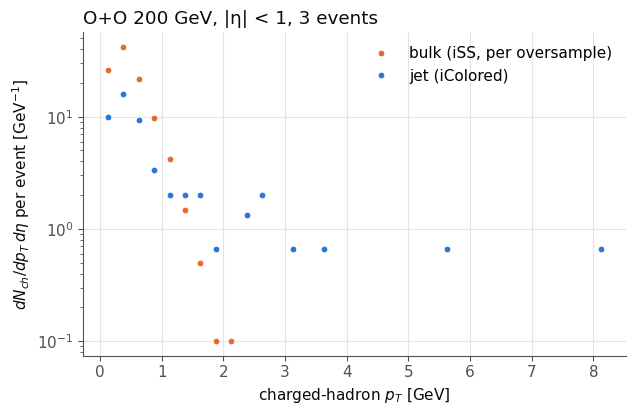

In [7]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"            # categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

bins = np.linspace(0, 10, 41)
width = np.diff(bins)
n_ev = len(jet_h.info["units"]["event"])
sel_j = charged_jet[abs(charged_jet.eta) < 1]
sel_b = charged_bulk[abs(charged_bulk.eta) < 1]
dn_jet = np.histogram(ak.to_numpy(ak.flatten(sel_j.pt)), bins)[0] / n_ev / width / 2.0
n_samples = int(ak.sum(ak.num(bulk_had, axis=1)))
dn_bulk = np.histogram(ak.to_numpy(ak.flatten(sel_b.pt, axis=None)), bins)[0] \
    * (len(bulk_h.info["unit_offsets"]) - 1) / n_samples / n_ev / width / 2.0

fig, ax = plt.subplots(figsize=(7, 4.2))
centers = 0.5 * (bins[1:] + bins[:-1])
# markers per filled bin: 3 events leave empty bins, which a line would bridge
for y, color, label in ((dn_bulk, ORANGE, "bulk (iSS, per oversample)"),
                        (dn_jet, BLUE, "jet (iColored)")):
    keep = y > 0
    ax.plot(centers[keep], y[keep], "o", ms=5, color=color, mec="white", mew=0.8,
            label=label)
ax.set_yscale("log")
ax.set_xlabel("charged-hadron $p_T$ [GeV]")
ax.set_ylabel(r"$dN_{ch}/dp_T\,d\eta$ per event [GeV$^{-1}$]")
ax.set_title("O+O 200 GeV, |η| < 1, 3 events", color=INK, loc="left")
ax.legend(frameon=False)
plt.show()

## 6 Jets with FastJet

FastJet's Python package takes the jagged awkward arrays directly: **one call clusters every
event** (or every oversample). Anti-kt, R = 0.4, hadrons at |η| < 2.

First the jets of the jet hadrons, all and charged only; the jets sit close to the hard
partons that started them (`initiators`, stored with the jet file).

In [8]:
import fastjet
import h5py
from jetscape.records import initiator_records

jdef = fastjet.JetDefinition(fastjet.antikt_algorithm, 0.4)
acc = jets_had[abs(jets_had.eta) < 2]
jets_all = fastjet.ClusterSequence(acc, jdef).inclusive_jets(min_pt=5.0)
jets_ch = fastjet.ClusterSequence(acc[js.select(acc, "charged")], jdef).inclusive_jets(min_pt=3.0)
jets_all = jets_all[ak.argsort(jets_all.pt, ascending=False)]
jets_ch = jets_ch[ak.argsort(jets_ch.pt, ascending=False)]

with h5py.File(jet_path) as f:          # the shower initiators, one table per event
    ini_rows, ini_off = f["initiators/data"][()], f["initiators/offsets"][()]
rows = []
for e in range(n_ev):
    ini = initiator_records(ini_rows[ini_off[e]:ini_off[e + 1]])
    hard = np.sort(np.hypot(ini["px"], ini["py"]))[::-1][:2]
    rows.append({"event": int(jet_h.info["units"]["event"][e]),
                 "hard partons pT": np.round(hard, 1).tolist(),
                 "jets pT (all)": np.round(ak.to_numpy(jets_all[e].pt), 1).tolist(),
                 "jets pT (charged)": np.round(ak.to_numpy(jets_ch[e].pt), 1).tolist()})
pd.DataFrame(rows).set_index("event")

,hard partons pT,jets pT (all),jets pT (charged)
event,,,
0,"[22.3, 19.1]","[21.2, 15.4]","[5.0, 4.2]"
1,"[26.8, 26.3]","[23.5, 13.0]","[9.8, 5.8, 4.8]"
2,"[22.9, 22.9]","[20.7, 20.0]",[16.9]


Then the bulk: **every oversample of every event** clustered at once
(events x oversamples x hadrons, flattened to oversamples x hadrons), giving the jets the
underlying event alone makes. And a jet **embedded in the bulk**: each event's jet hadrons
added to its first oversample, so the leading jet picks up the background under it.

In [9]:
flat_bulk = ak.flatten(bulk_had, axis=1)                       # all oversamples
flat_bulk = flat_bulk[abs(flat_bulk.eta) < 2]
bulk_jets = fastjet.ClusterSequence(flat_bulk, jdef).inclusive_jets(min_pt=5.0)
print(f"bulk alone: {len(flat_bulk)} oversamples, "
      f"{float(ak.mean(ak.num(bulk_jets))):.2f} jets > 5 GeV per oversample")

embedded = ak.concatenate([jets_had, bulk_had[:, 0]], axis=1)  # jet + one oversample
embedded = embedded[abs(embedded.eta) < 2]
emb_jets = fastjet.ClusterSequence(embedded, jdef).inclusive_jets(min_pt=5.0)
lead_emb = ak.to_numpy(ak.max(emb_jets.pt, axis=1))
lead_jet = ak.to_numpy(ak.fill_none(ak.max(jets_all.pt, axis=1), 0.0))
pd.DataFrame({"event": jet_h.info["units"]["event"],
              "leading jet pT, jet hadrons": np.round(lead_jet, 1),
              "leading jet pT, embedded": np.round(lead_emb, 1),
              "difference (background)": np.round(lead_emb - lead_jet, 1)}).set_index("event")

bulk alone: 60 oversamples, 0.52 jets > 5 GeV per oversample


,"leading jet pT, jet hadrons","leading jet pT, embedded",difference (background)
event,,,
0,21.2,23.6,2.4
1,23.5,25.9,2.4
2,20.7,24.1,3.4


One event in the η–φ plane: the bulk hadrons of its first oversample, the jet hadrons, and
the anti-kt jets of the jet hadrons (circles of R = 0.4). The jet file's hadrons spread over
the whole plane: iColoredHadronization strings the jet partons together with the beam
remnants, so the remnants' hadrons are in it too; the jets stand out by their pT.

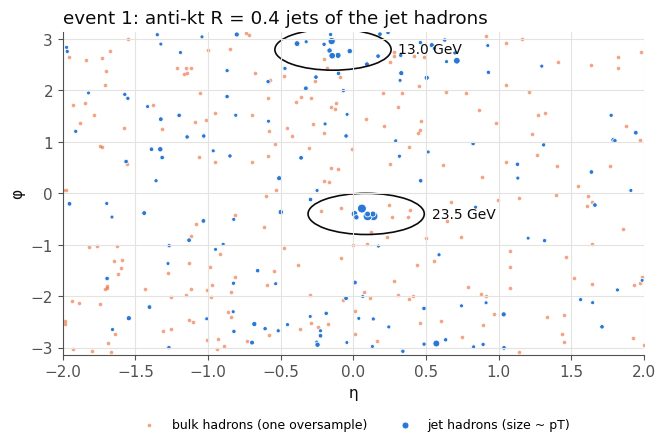

In [10]:
e = int(np.argmax(lead_jet))
b, j = bulk_had[e, 0], jets_had[e]
b, j = b[abs(b.eta) < 2], j[abs(j.eta) < 2]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(ak.to_numpy(b.eta), ak.to_numpy(b.phi), s=7, color=ORANGE, alpha=0.6,
           linewidths=0, label="bulk hadrons (one oversample)")
ax.scatter(ak.to_numpy(j.eta), ak.to_numpy(j.phi), s=8 + 6 * ak.to_numpy(j.pt), color=BLUE,
           edgecolors="white", linewidths=0.6, label="jet hadrons (size ~ pT)")
for jet in jets_all[e]:
    ax.add_patch(plt.Circle((float(jet.eta), float(jet.phi)), 0.4, fill=False, color=INK,
                            lw=1.2))
    ax.annotate(f"{float(jet.pt):.1f} GeV", (float(jet.eta) + 0.45, float(jet.phi)),
                va="center", color=INK, fontsize=10)
ax.set_xlim(-2, 2)
ax.set_ylim(-np.pi, np.pi)
ax.set_xlabel("η")
ax.set_ylabel("φ")
ax.set_title(f"event {int(jet_h.info['units']['event'][e])}: anti-kt R = 0.4 jets of the "
             "jet hadrons", color=INK, loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2,
          fontsize=9)
plt.show()

## Where to go from here

- **More events**: the production runs the same chain in jobs, `run_prod_oo_isr.py` and
  `run_jobs.sh` (`example/prod_OO_isr/README.md`); its hadron files read exactly as here.
- **Many files**: `HadronArray.from_h5(path, units=...)` per file, or
  `hadrons_h5.HadronFileReader` for whole campaigns with sample-averaged histograms.
- **Writing a module** (a jet energy loss, a hadronizer) in Python and running it in this
  chain: `PYTHONIC.md`, "Writing modules", and `example/python_modules/toy_modules_pythonic.py`.
- The files of this notebook are in `out_oo/` (git-ignored); the next cell removes them.

In [11]:
# import shutil; shutil.rmtree(OUT)      # uncomment to remove this notebook's output